# Causal modeling for clinical effects

## 1. Setup and sample preparation

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd

# project PATH
DATASET_NAME = "sz_meditation"
project_path_str="/scratch/repo_"+DATASET_NAME
project_path= Path(project_path_str)
sys.path.append(str(project_path))

# importing private libs and functions (imaging_arsenal version, need to import the parent dir as well)
private_lib_path = Path('/scratch/imaging_arsenal')
sys.path.append(str(private_lib_path))
sys.path.append(str(private_lib_path / 'utils_'))
print('private lib ready:',(private_lib_path / 'utils_private.py').exists())
from utils_.utils_private import report_cpu
report_cpu()

# data path
data_path = project_path / 'data' 
basic_time_Tag = "20240724"
fig_path = project_path / 'fig' 

# data
all_DKT_path = data_path / (DATASET_NAME+'_R_'+basic_time_Tag+'.csv')

# read data
all_df = pd.read_csv(all_DKT_path, index_col= None)
tmp_df=all_df.copy()

private lib ready: False


/opt/conda/lib/python3.9/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


Total CPUs: 12
Total Memory: 29.38 GB
Available Memory: 23.70 GB


In [2]:
# report major software version
import statsmodels 
import nilearn
import sys
import sklearn
import semopy
import seaborn as sns
import networkx as nx
# setup random seed
rand_seed = 24
np.random.seed(rand_seed)

print('python version:', sys.version)
print('numpy version:', np.__version__)
print('statsmodels version:', statsmodels.__version__)
print('nilearn version:', nilearn.__version__)
print('sklearn version:', sklearn.__version__)
print('semopy version:', semopy.__version__)
print('networkX version:', nx.__version__)
print('seaborn version:', sns.__version__)
print('random seed:', rand_seed)

python version: 3.9.12 | packaged by conda-forge | (main, Mar 24 2022, 23:25:59) 
[GCC 10.3.0]
numpy version: 1.26.4
statsmodels version: 0.14.5
nilearn version: 0.12.0
sklearn version: 1.4.2
semopy version: 2.3.11
networkX version: 3.1
seaborn version: 0.13.2
random seed: 24


In [3]:
# select clinical data out of full table (adding trajectory results)
test_cols = ['participant_id', 'group', 'session', 'age', 'age_of_onset', 'duration', 'CPZ_dose_0', 'marital_status']
outcome_dec_list = ['PANSS_SUM', 'PANSS_P_SUM', 'PANSS_N_SUM', 'PANSS_G_SUM']
outcome_inc_list = ['RBANS_sum', 'FFMQ']

base_list = [x+'_base' for x in outcome_dec_list + outcome_inc_list]

test_df = tmp_df[test_cols+outcome_dec_list+outcome_inc_list+base_list].copy()
test_df.rename(columns={'CPZ_dose_0': 'CPZ_dose'}, inplace=True)

## Computing dec rate:
test_df['PANSS_dec_rate'] = np.where( test_df['session'] == 0, 0,  # baseline explicitly set to zero
                                     (test_df['PANSS_SUM_base'] - test_df['PANSS_SUM']) / (test_df['PANSS_SUM_base'] - 30))
test_df['PANSS_P_dec_rate'] = np.where( test_df['session'] == 0, 0,  # baseline explicitly set to zero
                                       (test_df['PANSS_P_SUM_base'] - test_df['PANSS_P_SUM']) / (test_df['PANSS_P_SUM_base'] - 7))
test_df['PANSS_N_dec_rate'] = np.where( test_df['session'] == 0, 0,  # baseline explicitly set to zero
                                       (test_df['PANSS_N_SUM_base'] - test_df['PANSS_N_SUM']) / (test_df['PANSS_N_SUM_base'] - 7))
test_df['PANSS_G_dec_rate'] = np.where( test_df['session'] == 0, 0,  # baseline explicitly set to zero
                                       (test_df['PANSS_G_SUM_base'] - test_df['PANSS_G_SUM']) / (test_df['PANSS_G_SUM_base'] - 16))
test_df['RBANS_inc_rate'] = np.where(test_df['session'] == 0, 0,  # baseline explicitly set to zero
                                    (test_df['RBANS_sum'] - test_df['RBANS_sum_base']) / (test_df['RBANS_sum_base']))

test_df['FFMQ_inc_rate'] = np.where(test_df['session'] == 0, 0,  # baseline explicitly set to zero
                                    (test_df['FFMQ'] - test_df['FFMQ_base']) / (test_df['FFMQ_base']))
#
rate_list = ['PANSS_dec_rate', 'RBANS_inc_rate', 'FFMQ_inc_rate', 'PCS_inc_rate', 'MCS_inc_rate', 
             'PANSS_P_dec_rate', 'PANSS_N_dec_rate','PANSS_G_dec_rate']
test_df
test_df.head(3)

## 2. Main manuscript: average treatment-effect models

Linear mixed‐effects models (MEM) with random slopes for each participant to account for repeated measurements (baseline, 3 months, 8 months)

Between-participant variation in improvement trajectories was modeled using a random slope for elapsed time, without a random intercept. Because improvement outcomes were referenced to each participant’s baseline and were zero at baseline by definition, this specification anchored the random trajectory component at baseline while allowing individual deviations to accumulate over time. It also limited covariance complexity given the two post-baseline assessments. Visit was modeled categorically in the fixed effects, allowing nonlinear group-average trajectories. Sensitivity analyses examined the consequences of excluding baseline-zero observations and using participant-clustered uncertainty estimates.

In [4]:
## Data preparation for mixed-effects model
import statsmodels.api as sm
import statsmodels.formula.api as smf
basic_vars = ['participant_id', 'group', 'session', 'PANSS_dec_rate', 'RBANS_inc_rate', 'FFMQ_inc_rate']
covariates = ['RBANS_sum', 'PANSS_SUM_base', 'RBANS_sum_base', 'FFMQ_base', 'CPZ_dose'] # 'age', 'CPZ_dose', 'RBANS_sum',  

model_df = test_df[basic_vars+covariates].copy()
print('Missing data diagnostics:')
print(model_df.isnull().sum())
null_diagnostics = model_df.groupby(['participant_id','session']).apply(lambda x: x.isnull().sum())
#print(null_diagnostics[null_diagnostics.sum(axis=1) > 0])

model_df = model_df.dropna()
# get participant index
model_df['patient_idx'], _ = pd.factorize(model_df['participant_id'])
# numerical adjustment
model_df['group'] = model_df['group'].astype('category')
model_df.reset_index(drop=True, inplace=True)
print('Data shape:', model_df.shape)

# Confirm the existing clinical sample; no additional exclusions or imputation.
from IPython.display import display
assert len(model_df) == 186 and model_df['participant_id'].nunique() == 62
assert not model_df.duplicated(['participant_id', 'session']).any()
assert set(model_df['session']) == {0, 3, 8}
assert model_df.groupby('participant_id')['session'].nunique().eq(3).all()
assert model_df.groupby('participant_id')['group'].nunique().eq(1).all()
assert set(model_df['group'].astype(str)) == {'control', 'meditation'}
for column in ['PANSS_dec_rate', 'RBANS_inc_rate', 'FFMQ_inc_rate']:
    assert np.allclose(model_df.loc[model_df['session'].eq(0), column], 0)
    
clinical_fit_results = {}
clinical_fit_specs = {}
clinical_sample_counts = model_df.groupby(['group', 'session'], observed=True).agg(
    N=('participant_id', 'nunique')).reset_index()
display(clinical_sample_counts)

Missing data diagnostics:
participant_id    0
group             0
session           0
PANSS_dec_rate    1
RBANS_inc_rate    3
FFMQ_inc_rate     2
RBANS_sum         2
PANSS_SUM_base    0
RBANS_sum_base    3
FFMQ_base         3
CPZ_dose          0
dtype: int64
Data shape: (186, 12)


/tmp/ipykernel_19991/3509388165.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  null_diagnostics = model_df.groupby(['participant_id','session']).apply(lambda x: x.isnull().sum())


,group,session,N
0,control,0,30
1,control,3,30
2,control,8,30
3,meditation,0,32
4,meditation,3,32
5,meditation,8,32


### 2.1 PDR_ATE

***`PANSS_dec_rate ~ C(group)\*C(session) + PANSS_SUM_base`***

In [5]:
import statsmodels.api as sm
import statsmodels.formula.api as smf
# Fit directly on model_df; no need to create a scaled mem_df
panss_model_str = "PANSS_dec_rate ~ C(group)*C(session) + PANSS_SUM_base"
model_mem = smf.mixedlm( 
    formula=panss_model_str,
    data=model_df,
    groups=model_df["patient_idx"], 
    re_formula="~0+session",
)
panss_ate_res = model_mem.fit(method='powell', reml=True)
print('Model:', panss_model_str)
print(panss_ate_res.summary())
clinical_fit_results['PDR_ATE'] = panss_ate_res
clinical_fit_specs['PDR_ATE'] = {'Outcome': 'PDR', 'Role': 'Main', 'Moderator': '', 'Formula': panss_model_str}

Model: PANSS_dec_rate ~ C(group)*C(session) + PANSS_SUM_base
                      Mixed Linear Model Regression Results
Model:                   MixedLM        Dependent Variable:        PANSS_dec_rate
No. Observations:        186            Method:                    REML          
No. Groups:              62             Scale:                     0.0007        
Min. group size:         3              Log-Likelihood:            302.8923      
Max. group size:         3              Converged:                 Yes           
Mean group size:         3.0                                                     
---------------------------------------------------------------------------------
                                       Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------------------------------
Intercept                              -0.018    0.018 -0.974 0.330 -0.054  0.018
C(group)[T.meditation]                 -0.000    0.007 -0.0

/opt/conda/lib/python3.9/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


## Visualization

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

def extract_marginal_means(model_res, data_df):
    """
    Dynamically extracts Estimated Marginal Means and 95% CIs.
    Automatically detects covariates and sets them to their sample mean.
    """
    fixed_params = model_res.params[model_res.cov_params().columns]
    cov_matrix = model_res.cov_params()
    
    combos = [('control', 0), ('control', 3), ('control', 8),
              ('meditation', 0), ('meditation', 3), ('meditation', 8)]
    
    results_list = []
    
    for g, s in combos:
        L = np.zeros(len(fixed_params))
        
        for i, name in enumerate(fixed_params.index):
            if name == 'Intercept':
                L[i] = 1
            elif name == 'C(group)[T.meditation]' and g == 'meditation':
                L[i] = 1
            elif name == f'C(session)[T.{s}]':
                L[i] = 1
            elif name == f'C(group)[T.meditation]:C(session)[T.{s}]' and g == 'meditation':
                L[i] = 1
            # AUTOMATIC COVARIATE HANDLING:
            elif name in data_df.columns:
                L[i] = data_df[name].mean() # Automatically grabs the mean from your dataframe!
                
        # Matrix multiplication
        mean_est = np.dot(L, fixed_params)
        var_est  = np.dot(L, np.dot(cov_matrix, L))
        se_est   = np.sqrt(var_est)
        
        z_crit = 1.96 
        results_list.append({
            'group': g, 'session': s, 
            'mean_est': mean_est, 
            'ci_lower': mean_est - z_crit * se_est, 
            'ci_upper': mean_est + z_crit * se_est
        })
        
    return pd.DataFrame(results_list)

def format_annotation(model_res, month):
    """Formats the ATE and p-value string for the plot annotations."""
    interaction_term = f'C(group)[T.meditation]:C(session)[T.{month}]'
    ate_val = model_res.params[interaction_term]
    p_val = model_res.pvalues[interaction_term]
    
    if p_val > 0.05:
        p_str = f"$p={p_val:.3f}$"
    elif p_val > 0.01:
        p_str = f"$p={p_val:.3f}$\n*"
    elif p_val > 0.001:
        p_str = f"$p={p_val:.3f}$\n**"
    else:
        p_str = "$p<0.001$\n***"
        
    # Multiply by 100 here solely for the visual string output
    return f"ATE={ate_val * 100:.1f}%\n{p_str}"

def plot_clinical_trajectory(model_res, ylabel, data_df=None, save_path=None):
    """
    Main plotting function. Generates a publication-ready longitudinal trajectory.
    """
    sns.set_theme(style="whitegrid", font_scale=1.2)
    colors = {
        'meditation': {'main': '#4393c3', 'edge': '#2166ac'},
        'control': {'main': '#7fbc41', 'edge': '#276419'}
    }
    
    df = extract_marginal_means(model_res, data_df)
    med_df = df.query("group == 'meditation'").sort_values('session').reset_index(drop=True)
    ctrl_df = df.query("group == 'control'").sort_values('session').reset_index(drop=True)
    sessions = ctrl_df['session'].values
    
    fig, ax = plt.subplots(figsize=(12, 10))
    
    # Plot Control (GRP)
    ax.errorbar(sessions, ctrl_df['mean_est'],
                yerr=[ctrl_df['mean_est'] - ctrl_df['ci_lower'], ctrl_df['ci_upper'] - ctrl_df['mean_est']],
                fmt='-o', linewidth=6, markersize=24, elinewidth=3, capsize=8,
                color=colors['control']['main'], markeredgecolor=colors['control']['edge'], 
                markeredgewidth=4, label='GRP')

    # Plot Meditation
    ax.errorbar(sessions, med_df['mean_est'],
                yerr=[med_df['mean_est'] - med_df['ci_lower'], med_df['ci_upper'] - med_df['mean_est']],
                fmt='-o', linewidth=6, markersize=24, elinewidth=3, capsize=8,
                color=colors['meditation']['main'], markeredgecolor=colors['meditation']['edge'], 
                markeredgewidth=4, label='Meditation')

    # Annotations (ATE and p-values)
    marker_x = med_df['session'].values[1:3]
    # Adjusted offset for decimal scale (e.g., 0.025 instead of 2.5)
    marker_y = med_df['ci_upper'].values[1:3] + 0.025 
    
    texts = [format_annotation(model_res, 3), format_annotation(model_res, 8)]
    for xi, yi, text_ in zip(marker_x, marker_y, texts):
        ax.text(xi, yi, text_, fontsize=20, ha='center', va='bottom', color='black', weight='bold')

    # Formatting & Cleanup
    sns.despine(left=True, ax=ax)
    ax.xaxis.grid(False) 
    
    ax.set_xlim(-0.5, 8.8)
    ax.set_xticks(sessions)
    ax.set_xticklabels(['Baseline', '3 Months', '8 Months'], fontsize=20)
    
    # Format y-ticks as percentages natively
    ax.set_ylim(-0.08, 0.55) # Adjusted limits for raw decimal data
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1.0, decimals=0))
    ax.tick_params(axis='y', labelsize=20)
    
    ax.set_xlabel('Time (Months)', fontsize=22, labelpad=15)
    ax.set_ylabel(ylabel, fontsize=22, labelpad=15)
    
    custom_handles = [
        Line2D([0], [0], color=colors['meditation']['main'], linewidth=4, 
               marker='o', markersize=18, markeredgewidth=3, 
               markeredgecolor=colors['meditation']['edge'], label='Meditation'),
        Line2D([0], [0], color=colors['control']['main'], linewidth=4, 
               marker='o', markersize=18, markeredgewidth=3, 
               markeredgecolor=colors['control']['edge'], label='GRP')
    ]

    ax.legend(
        handles=custom_handles, 
        loc='upper left', 
        bbox_to_anchor=(0.02, 0.98), 
        frameon=True,
        prop={'weight': 'bold', 'size': 20},
        borderpad=1.2,      
        labelspacing=1.2,   
        handletextpad=1.0,  
        handlelength=2.0    
    )
    
    plt.tight_layout()
    
    if save_path:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(save_path, dpi=330)
        print(f"Figure saved at: {save_path}")
    else:
        plt.show()

Figure saved at: /scratch/repo_sz_meditation/fig/pdr_mlm_2026.jpg


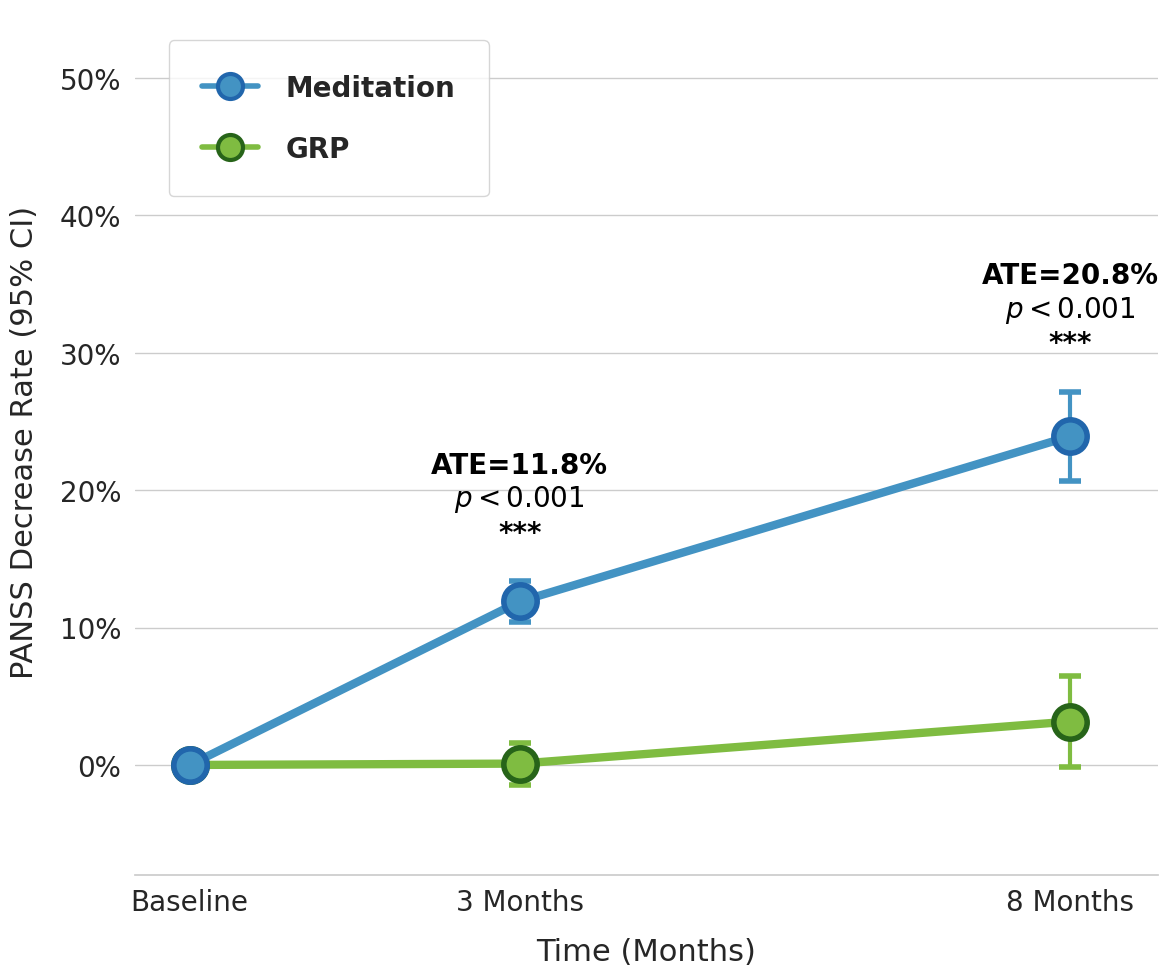

In [7]:
# Now generate the plot with a single, clean line:
plot_clinical_trajectory(
    model_res=panss_ate_res, 
    ylabel='PANSS Decrease Rate (95% CI)', 
    data_df=model_df,
    save_path=fig_path/'pdr_mlm_2026.jpg'
)

### 2.2 RIR_ATE

***`RBANS_inc_rate ~ C(group)*C(session) + RBANS_sum_base`***

In [8]:
# Mixed-effects model
rbans_model_str = "RBANS_inc_rate ~ C(group)*C(session) + RBANS_sum_base" # or time + group + time:group + RBANS_sum_base  + RBANS_sum_base + RBANS_sum_base
model_mem = smf.mixedlm( 
    formula=rbans_model_str,
    data=model_df,
    groups=model_df["patient_idx"],  # numeric random slope; no random intercept
    re_formula="~0+session",
)
rbans_ate_res = model_mem.fit(method='powell', reml=True)
print('Model:', rbans_model_str)
print(rbans_ate_res.summary())
clinical_fit_results['RIR_ATE'] = rbans_ate_res
clinical_fit_specs['RIR_ATE'] = {'Outcome': 'RIR', 'Role': 'Main', 'Moderator': '', 'Formula': rbans_model_str}

Model: RBANS_inc_rate ~ C(group)*C(session) + RBANS_sum_base
                      Mixed Linear Model Regression Results
Model:                   MixedLM        Dependent Variable:        RBANS_inc_rate
No. Observations:        186            Method:                    REML          
No. Groups:              62             Scale:                     0.0045        
Min. group size:         3              Log-Likelihood:            168.6062      
Max. group size:         3              Converged:                 Yes           
Mean group size:         3.0                                                     
---------------------------------------------------------------------------------
                                       Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------------------------------
Intercept                               0.011    0.035  0.314 0.753 -0.058  0.080
C(group)[T.meditation]                  0.002    0.018  0.1

/opt/conda/lib/python3.9/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Figure saved at: /scratch/repo_sz_meditation/fig/rir_mlm_2026.jpg


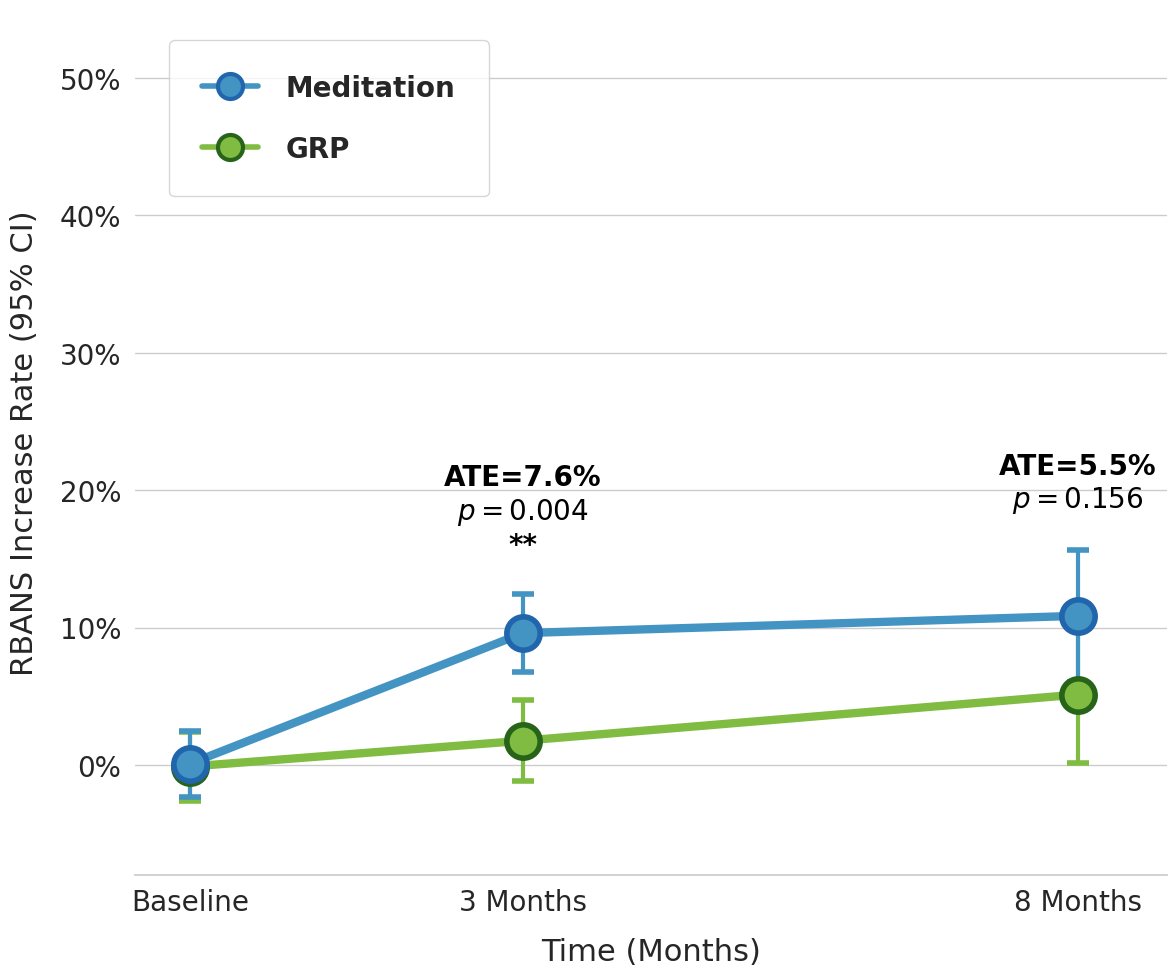

In [9]:
# Now generate the plot with a single, clean line:
plot_clinical_trajectory(
    model_res=rbans_ate_res, 
    ylabel='RBANS Increase Rate (95% CI)', 
    data_df=model_df,
    save_path=fig_path/'rir_mlm_2026.jpg'
)

### 2.3 FFMQ_ATE

***`FFMQ_inc_rate ~ C(group)*C(session) + FFMQ_base`***

In [10]:
# Mixed-effects model
FFMQ_model_str = "FFMQ_inc_rate ~ C(group)*C(session) + FFMQ_base" # or time + group + time:group + RBANS_sum_base  + RBANS_sum_base + RBANS_sum_base
model_mem = smf.mixedlm( 
    formula=FFMQ_model_str,
    data=model_df,
    groups=model_df["patient_idx"], 
    re_formula="~0+session",
)
ffmq_ate_res = model_mem.fit(method='powell', reml=True)
print('Model:', FFMQ_model_str)
print(ffmq_ate_res.summary())
clinical_fit_results['FFMQ_ATE'] = ffmq_ate_res
clinical_fit_specs['FFMQ_ATE'] = {'Outcome': 'FFMQ', 'Role': 'Secondary', 'Moderator': '', 'Formula': FFMQ_model_str}

Model: FFMQ_inc_rate ~ C(group)*C(session) + FFMQ_base
                      Mixed Linear Model Regression Results
Model:                    MixedLM        Dependent Variable:        FFMQ_inc_rate
No. Observations:         186            Method:                    REML         
No. Groups:               62             Scale:                     0.0059       
Min. group size:          3              Log-Likelihood:            119.8044     
Max. group size:          3              Converged:                 Yes          
Mean group size:          3.0                                                    
---------------------------------------------------------------------------------
                                       Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------------------------------
Intercept                               0.091    0.027  3.376 0.001  0.038  0.143
C(group)[T.meditation]                  0.002    0.020  0.089 0.9

/opt/conda/lib/python3.9/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Figure saved at: /scratch/repo_sz_meditation/fig/FFMQ_mlm_2026.jpg


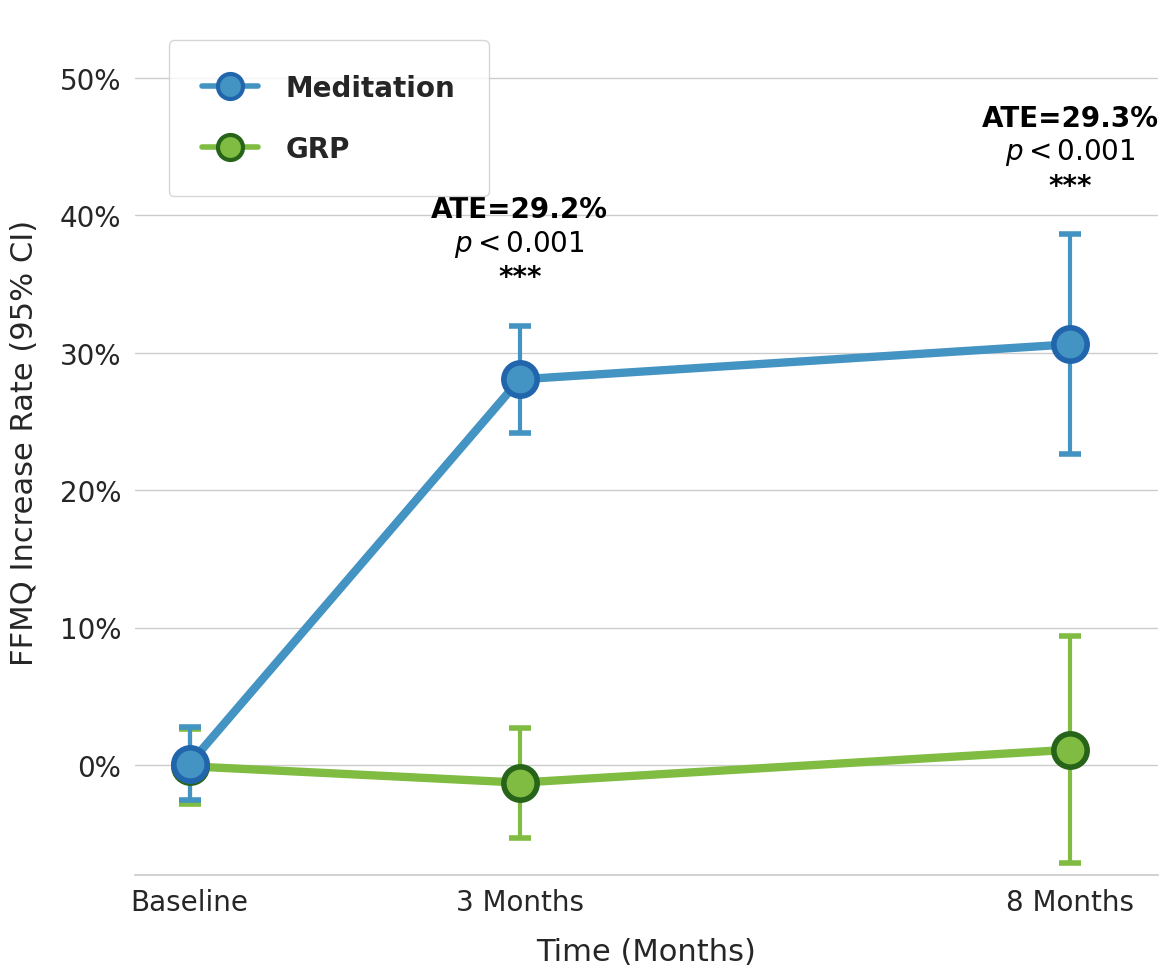

In [11]:
# Now generate the plot with a single, clean line:
plot_clinical_trajectory(
    model_res=ffmq_ate_res, 
    ylabel='FFMQ Increase Rate (95% CI)', 
    data_df=model_df,
    save_path=fig_path/'FFMQ_mlm_2026.jpg'
)

## 3. Supplement:  CATE / baseline effect-modification models

### 3.1 PDR_CATE_RBANS

`PANSS_dec_rate ~ C(group)*C(session) + PANSS_SUM_base + RBANS_sum_base + C(group):RBANS_sum_base`

In [12]:
# Mixed-effects model
panss_model_str = "PANSS_dec_rate ~ C(group)*C(session) + PANSS_SUM_base + RBANS_sum_base + C(group):RBANS_sum_base" 
model_mem = smf.mixedlm( 
    formula=panss_model_str,
    data=model_df,
    groups=model_df["patient_idx"], 
    re_formula="~0+session",
)
panss_cate_rbans_res = model_mem.fit(method='powell', reml=True)
print('Model:', panss_model_str)
print(panss_cate_rbans_res.summary())
clinical_fit_results['PDR_CATE_RBANS'] = panss_cate_rbans_res
clinical_fit_specs['PDR_CATE_RBANS'] = {'Outcome': 'PDR', 'Role': 'Supplement_CATE', 'Moderator': 'RBANS_sum_base', 'Formula': panss_model_str}

Model: PANSS_dec_rate ~ C(group)*C(session) + PANSS_SUM_base + RBANS_sum_base + C(group):RBANS_sum_base
                      Mixed Linear Model Regression Results
Model:                   MixedLM        Dependent Variable:        PANSS_dec_rate
No. Observations:        186            Method:                    REML          
No. Groups:              62             Scale:                     0.0007        
Min. group size:         3              Log-Likelihood:            290.1497      
Max. group size:         3              Converged:                 Yes           
Mean group size:         3.0                                                     
---------------------------------------------------------------------------------
                                       Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------------------------------
Intercept                              -0.025    0.033 -0.756 0.450 -0.089  0.039
C(group)[T.medit

/opt/conda/lib/python3.9/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


### 3.2 PDR_CATE_CPZ

***`PANSS_dec_rate ~ C(group)*C(session) + PANSS_SUM_base + CPZ_dose + C(group):CPZ_dose`***

In [13]:
# Mixed-effects model
panss_model_str = "PANSS_dec_rate ~ C(group)*C(session) + PANSS_SUM_base + CPZ_dose + C(group):CPZ_dose" # or time + group + time:group + RBANS_sum_base  + RBANS_sum_base + RBANS_sum_base
model_mem = smf.mixedlm( 
    formula=panss_model_str,
    data=model_df,
    groups=model_df["patient_idx"], 
    re_formula="~0+session",
)
panss_cate_cpz_res = model_mem.fit(method='powell', reml=True)
print('Model:', panss_model_str)
print(panss_cate_cpz_res.summary())
clinical_fit_results['PDR_CATE_CPZ'] = panss_cate_cpz_res
clinical_fit_specs['PDR_CATE_CPZ'] = {'Outcome': 'PDR', 'Role': 'Supplement_CATE', 'Moderator': 'CPZ_dose', 'Formula': panss_model_str}

Model: PANSS_dec_rate ~ C(group)*C(session) + PANSS_SUM_base + CPZ_dose + C(group):CPZ_dose
                      Mixed Linear Model Regression Results
Model:                   MixedLM        Dependent Variable:        PANSS_dec_rate
No. Observations:        186            Method:                    REML          
No. Groups:              62             Scale:                     0.0007        
Min. group size:         3              Log-Likelihood:            283.8260      
Max. group size:         3              Converged:                 Yes           
Mean group size:         3.0                                                     
---------------------------------------------------------------------------------
                                       Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------------------------------
Intercept                              -0.014    0.020 -0.669 0.503 -0.053  0.026
C(group)[T.meditation]      

/opt/conda/lib/python3.9/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


### 3.3 RIR_CATE_RBANS

***`RBANS_inc_rate ~ C(group)*C(session) + RBANS_sum_base + C(group):RBANS_sum_base`***

In [14]:
# Mixed-effects model
rbans_model_str = "RBANS_inc_rate ~ C(group)*C(session) + RBANS_sum_base + C(group):RBANS_sum_base" 
model_mem = smf.mixedlm( 
    formula=rbans_model_str,
    data=model_df,
    groups=model_df["patient_idx"],  # numeric random slope; no random intercept
    re_formula="~0+session",
)
rbans_cate_rbans_res = model_mem.fit(method='powell', reml=True)
print('Model:', rbans_model_str)
print(rbans_cate_rbans_res.summary())
clinical_fit_results['RIR_CATE_RBANS'] = rbans_cate_rbans_res
clinical_fit_specs['RIR_CATE_RBANS'] = {'Outcome': 'RIR', 'Role': 'Supplement_CATE', 'Moderator': 'RBANS_sum_base', 'Formula': rbans_model_str}

Model: RBANS_inc_rate ~ C(group)*C(session) + RBANS_sum_base + C(group):RBANS_sum_base
                      Mixed Linear Model Regression Results
Model:                   MixedLM        Dependent Variable:        RBANS_inc_rate
No. Observations:        186            Method:                    REML          
No. Groups:              62             Scale:                     0.0045        
Min. group size:         3              Log-Likelihood:            162.7324      
Max. group size:         3              Converged:                 Yes           
Mean group size:         3.0                                                     
---------------------------------------------------------------------------------
                                       Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------------------------------
Intercept                               0.002    0.054  0.045 0.964 -0.104  0.109
C(group)[T.meditation]           

/opt/conda/lib/python3.9/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


### 3.4 RIR_CATE_CPZ

***`RBANS_inc_rate ~ C(group)*C(session) + RBANS_sum_base + CPZ_dose + C(group):CPZ_dose`***

In [15]:
# Mixed-effects model
rbans_model_str = "RBANS_inc_rate ~ C(group)*C(session) + RBANS_sum_base + CPZ_dose + C(group):CPZ_dose" 
model_mem = smf.mixedlm( 
    formula=rbans_model_str,
    data=model_df,
    groups=model_df["patient_idx"],  # numeric random slope; no random intercept
    re_formula="~0+session",
)
rbans_cate_cpz_res = model_mem.fit(method='powell', reml=True)
print('Model:', rbans_model_str)
print(rbans_cate_cpz_res.summary())
clinical_fit_results['RIR_CATE_CPZ'] = rbans_cate_cpz_res
clinical_fit_specs['RIR_CATE_CPZ'] = {'Outcome': 'RIR', 'Role': 'Supplement_CATE', 'Moderator': 'CPZ_dose', 'Formula': rbans_model_str}

Model: RBANS_inc_rate ~ C(group)*C(session) + RBANS_sum_base + CPZ_dose + C(group):CPZ_dose
                      Mixed Linear Model Regression Results
Model:                   MixedLM        Dependent Variable:        RBANS_inc_rate
No. Observations:        186            Method:                    REML          
No. Groups:              62             Scale:                     0.0045        
Min. group size:         3              Log-Likelihood:            152.5352      
Max. group size:         3              Converged:                 Yes           
Mean group size:         3.0                                                     
---------------------------------------------------------------------------------
                                       Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------------------------------
Intercept                               0.041    0.043  0.947 0.343 -0.044  0.126
C(group)[T.meditation]      

/opt/conda/lib/python3.9/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


## 4. Optional existing covariate-adjustment sensitivities

 These are the original extra-adjustment models.

### 4.1 PDR_adjusted

***`PANSS_dec_rate ~ C(group)*C(session) + PANSS_SUM_base + RBANS_sum_base + CPZ_dose`***

In [16]:
 # Mixed-effects model
panss_model_str = "PANSS_dec_rate ~ C(group)*C(session) + PANSS_SUM_base + RBANS_sum_base + CPZ_dose" # or time + group + time:group + RBANS_sum_base  + RBANS_sum_base + RBANS_sum_base
model_mem = smf.mixedlm( 
    formula=panss_model_str,
    data=model_df,
    groups=model_df["patient_idx"], 
    re_formula="~0+session",
)
panss_adjusted_res = model_mem.fit(method='powell', reml=True)
print('Model:', panss_model_str)
print(panss_adjusted_res.summary())
clinical_fit_results['PDR_adjusted'] = panss_adjusted_res
clinical_fit_specs['PDR_adjusted'] = {'Outcome': 'PDR', 'Role': 'Optional_adjustment_sensitivity', 'Moderator': '', 'Formula': panss_model_str}

Model: PANSS_dec_rate ~ C(group)*C(session) + PANSS_SUM_base + RBANS_sum_base + CPZ_dose
                      Mixed Linear Model Regression Results
Model:                   MixedLM        Dependent Variable:        PANSS_dec_rate
No. Observations:        186            Method:                    REML          
No. Groups:              62             Scale:                     0.0007        
Min. group size:         3              Log-Likelihood:            286.5347      
Max. group size:         3              Converged:                 Yes           
Mean group size:         3.0                                                     
---------------------------------------------------------------------------------
                                       Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------------------------------
Intercept                              -0.043    0.026 -1.651 0.099 -0.095  0.008
C(group)[T.meditation]         

/opt/conda/lib/python3.9/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


### 4.2 RIR_adjusted

***`RBANS_inc_rate ~ C(group)*C(session) + PANSS_SUM_base + RBANS_sum_base + CPZ_dose`***

In [17]:
# Mixed-effects model
rbans_model_str = "RBANS_inc_rate ~ C(group)*C(session) + PANSS_SUM_base + RBANS_sum_base + CPZ_dose" # or time + group + time:group + RBANS_sum_base  + RBANS_sum_base + RBANS_sum_base
model_mem = smf.mixedlm( 
    formula=rbans_model_str,
    data=model_df,
    groups=model_df["patient_idx"],  # numeric random slope; no random intercept
    re_formula="~0+session",
)
rbans_adjusted_res = model_mem.fit(method='powell', reml=True)
print('Model:', rbans_model_str)
print(rbans_adjusted_res.summary())
clinical_fit_results['RIR_adjusted'] = rbans_adjusted_res
clinical_fit_specs['RIR_adjusted'] = {'Outcome': 'RIR', 'Role': 'Optional_adjustment_sensitivity', 'Moderator': '', 'Formula': rbans_model_str}

/opt/conda/lib/python3.9/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Model: RBANS_inc_rate ~ C(group)*C(session) + PANSS_SUM_base + RBANS_sum_base + CPZ_dose
                      Mixed Linear Model Regression Results
Model:                   MixedLM        Dependent Variable:        RBANS_inc_rate
No. Observations:        186            Method:                    REML          
No. Groups:              62             Scale:                     0.0045        
Min. group size:         3              Log-Likelihood:            153.9868      
Max. group size:         3              Converged:                 Yes           
Mean group size:         3.0                                                     
---------------------------------------------------------------------------------
                                       Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------------------------------
Intercept                               0.047    0.062  0.749 0.454 -0.075  0.168
C(group)[T.meditation]         

## 5. Reporting tables from the fitted models

ATE terms are retained. CATE tables separately identify the group-by-baseline modifier coefficient and all fixed parameters. Estimates are on the original rate scale; percentage-point columns multiply by 100. All tests and intervals remain nominal and model-based. No multiplicity correction or alternative uncertainty estimator is added here.

In [18]:
ate_model_ids = ['PDR_ATE', 'RIR_ATE', 'FFMQ_ATE']
cate_model_ids = ['PDR_CATE_RBANS', 'PDR_CATE_CPZ',
                  'RIR_CATE_RBANS', 'RIR_CATE_CPZ']
adjusted_model_ids = ['PDR_adjusted', 'RIR_adjusted']
report_model_ids = ate_model_ids + cate_model_ids + adjusted_model_ids
missing_models = [name for name in report_model_ids if name not in clinical_fit_results]
assert not missing_models, (
    f'Missing fitted models: {missing_models}. Run the relevant fitting cells first. '
)

clinical_fixed_rows = []
for model_id in report_model_ids:
    result = clinical_fit_results[model_id]
    info = clinical_fit_specs[model_id]
    assert result.model.formula == info['Formula'], f'Formula/specification mismatch: {model_id}.'
    assert int(result.nobs) == len(model_df), f'Unexpected fitted row count: {model_id}.'
    assert int(result.model.n_groups) == model_df['participant_id'].nunique(), (
        f'Unexpected fitted participant count: {model_id}.'
    )
    names = list(result.fe_params.index)
    fixed_ci = result.conf_int().loc[names]
    visit_terms = {f'C(group)[T.meditation]:C(session)[T.{month}]': month
                   for month in [3, 8]}
    assert set(visit_terms).issubset(names), f'Check group/visit coding for {model_id}.'
    moderator = info.get('Moderator', '')
    modifier_term = 'C(group)[T.meditation]:' + moderator
    if model_id in cate_model_ids:
        assert modifier_term in names, f'Missing modifier term for {model_id}.'

    for term in names:
        month = visit_terms.get(term)
        is_modifier = model_id in cate_model_ids and term == modifier_term
        if is_modifier:
            interpretation = ('Common-across-visits group x baseline coefficient, '
                              'per baseline unit; not visit-specific moderation of change')
        elif month is not None:
            interpretation = 'Group x visit relative to fitted baseline arm difference'
        else:
            interpretation = 'Fixed-effect coefficient conditional on the other model terms'
        record = {
            'Model': model_id, 'Outcome': info['Outcome'],
            'Role': ('Supplement_covariate_adjustment' if model_id in adjusted_model_ids
                     else info['Role']),
            'Moderator': moderator, 'Term': term, 'Month': month,
            'Key_result': (is_modifier if model_id in cate_model_ids else month is not None),
            'Estimate': float(result.fe_params[term]),
            'SE': float(result.bse[term]),
            'CI95_low': float(fixed_ci.loc[term].iloc[0]),
            'CI95_high': float(fixed_ci.loc[term].iloc[1]),
            'p_nominal': float(result.pvalues[term]),
            'Interpretation': interpretation,
            'Formula': info['Formula'],
            'Random_effects': 'Numeric elapsed-month slope by participant; no random intercept',
            'Random_formula': '~0+session', 'Session_months': '0, 3, 8',
            'Reference_group': 'control', 'Reference_session_month': 0,
            'Estimator': 'REML' if result.reml else 'ML',
            'Optimizer': 'powell',
            'Uncertainty': 'Model-based 95% Wald intervals; nominal two-sided p-values',
            'Units': 'Outcome proportion per design-matrix unit; percentage-point columns multiply by 100',
            'N': int(result.model.n_groups), 'Rows': int(result.nobs),
            'Converged': bool(result.converged),
            'Random_slope_variance': float(np.asarray(result.cov_re)[0, 0]),
            'Residual_variance': float(result.scale),
        }
        for key in ['Estimate', 'SE', 'CI95_low', 'CI95_high']:
            record[key + '_percentage_points'] = 100 * record[key]
        clinical_fixed_rows.append(record)

# Exactly three reporting tables. Supplementary tables contain every fixed
# coefficient; Key_result identifies the focal modifier or group x visit terms.
clinical_all_fixed = pd.DataFrame(clinical_fixed_rows)
clinical_all_fixed['Month'] = clinical_all_fixed['Month'].astype('Int64')
main_ate_table = clinical_all_fixed.loc[
    clinical_all_fixed['Model'].isin(ate_model_ids) & clinical_all_fixed['Key_result']
].copy().reset_index(drop=True)
supp_cate_table = clinical_all_fixed.loc[
    clinical_all_fixed['Model'].isin(cate_model_ids)
].copy().reset_index(drop=True)
supp_covadj_table = clinical_all_fixed.loc[
    clinical_all_fixed['Model'].isin(adjusted_model_ids)
].copy().reset_index(drop=True)
assert len(main_ate_table) == 6
assert supp_cate_table['Key_result'].sum() == 4
assert supp_covadj_table['Key_result'].sum() == 4

print('ATE: original group x visit contrasts; FFMQ remains secondary.')
display(main_ate_table[['Outcome', 'Month', 'Estimate_percentage_points',
    'CI95_low_percentage_points', 'CI95_high_percentage_points', 'p_nominal']])
print('CATE: focal coefficients shown; the saved table also includes all other fixed coefficients and specifications.')
display(supp_cate_table.loc[supp_cate_table['Key_result'],
    ['Outcome', 'Moderator', 'Estimate', 'CI95_low', 'CI95_high', 'p_nominal']])
print('Covariate-adjusted sensitivity: focal contrasts shown; all fixed coefficients and specifications are saved.')
display(supp_covadj_table.loc[supp_covadj_table['Key_result'],
    ['Outcome', 'Month', 'Estimate_percentage_points',
     'CI95_low_percentage_points', 'CI95_high_percentage_points', 'p_nominal']])

ATE: original group x visit contrasts; FFMQ remains secondary.


,Outcome,Month,Estimate_percentage_points,CI95_low_percentage_points,CI95_high_percentage_points,p_nominal
0,PDR,3,11.807455,9.316596,14.298313,1.530647e-20
1,PDR,8,20.771891,15.942690,25.601091,3.444450e-17
2,RIR,3,7.618405,2.395112,12.841697,4.253878e-03
3,RIR,8,5.518368,-2.096959,13.133696,1.555298e-01
4,FFMQ,3,29.172707,22.407335,35.938079,2.876158e-17
5,FFMQ,8,29.326470,17.206868,41.446071,2.109580e-06


CATE: focal coefficients shown; the saved table also includes all other fixed coefficients and specifications.


,Outcome,Moderator,Estimate,CI95_low,CI95_high,p_nominal
8,PDR,RBANS_sum_base,0.000423,-0.000493,0.001338,0.365395
17,PDR,CPZ_dose,0.000018,-0.000059,0.000095,0.643522
25,RIR,RBANS_sum_base,-0.000230,-0.002387,0.001928,0.834654
34,RIR,CPZ_dose,-0.000061,-0.000238,0.000117,0.503852


Covariate-adjusted sensitivity: focal contrasts shown; all fixed coefficients and specifications are saved.


,Outcome,Month,Estimate_percentage_points,CI95_low_percentage_points,CI95_high_percentage_points,p_nominal
4,PDR,3,11.807455,9.319187,14.295723,1.397609e-20
5,PDR,8,20.771891,15.958098,25.585683,2.734093e-17
13,RIR,3,7.618405,2.394176,12.842634,4.260755e-03
14,RIR,8,5.518368,-2.044543,13.081279,1.526851e-01


In [19]:
from datetime import datetime
clinical_reporting_dir = data_path / 'clinical' / (
    'Clinical_reporting_' + datetime.now().strftime('%Y%m%d_%H%M%S_%f'))
clinical_reporting_dir.mkdir(parents=True, exist_ok=False)
for table, filename in [
    (main_ate_table, 'ATE_results.csv'),
    (supp_cate_table, 'Supplement_CATE_results.csv'),
    (supp_covadj_table, 'Supplement_covariate_adjustment_results.csv'),
]:
    table.to_csv(clinical_reporting_dir / filename, index=False)
print('Saved exactly three result tables to:', clinical_reporting_dir)

Saved exactly three result tables to: /scratch/repo_sz_meditation/data/clinical/Clinical_reporting_20261015_032044_460125
